# Supplementary Fig. 8: information capacity as a function of the dimensionality of the population

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce Supplementary Fig. 8: manifold information capacity, divided by its lower bound, of the whole ground truth (blue, only at 50 dimensions), of random samples of the ground truth with as many neurons as Kilosort4 has sorted single-units (orange, undersampling) and of samples that also reproduce the unit types of Kilosort4 (green, undersampling and selection bias), as a function of the dimensionality of a Gaussian random projection (50 to 1,600). Chance is 1.

**method (as in the paper's notebook `supp_fig8_supp_capacity_vs_dim.ipynb`)**
* the capacity of each population is computed on 200 bootstraps of the sampled neurons (evoked simulation, 1 hour); the bootstrapped capacities are read from the csv file of the paper (`igeometrics_by_dimensionality.csv`); they are **not recomputed** here (the capacity analysis needs the `mftma` package and takes about 1 h 34 min)
* box plots (notch, 200 bootstraps), the boxes of the same colour are pooled over the populations of that sampling scheme, as in the paper

Run time: about 10 seconds. Source data and svg: `figures/8_source_data/supp_fig8/`.

In [1]:
# SETUP PACKAGES
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
warnings.filterwarnings("ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)

IGEOM_DIM = "dataset/01_intermediate/neural_code/npx_evoked/igeometrics_by_dimensionality.csv"
OUT = "figures/8_source_data/supp_fig8"
os.makedirs(OUT, exist_ok=True)

# SETUP PLOT
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's axes were drawn without Arial (matplotlib default font); legend and "Chance" are Arial
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 400}

In [ ]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Source data: bootstrapped capacities

In [2]:
igeom_df = pd.read_csv(IGEOM_DIM)
df = igeom_df.rename(columns={"Capacity": "capacity_over_lower_bound", "Sorter": "population", "Sampling scheme": "sampling_scheme"})
df["population"] = df["population"].replace({"ground_truth": "ground truth"})
df["bootstrap"] = df.groupby(["population", "sampling_scheme", "dimensionality"]).cumcount()
df = df[["population", "sampling_scheme", "dimensionality", "bootstrap", "capacity_over_lower_bound"]]
assert (df.groupby(["population", "sampling_scheme", "dimensionality"]).size() == 200).all(), "200 bootstraps each"
display(df.groupby(["sampling_scheme", "dimensionality"], sort=False)["capacity_over_lower_bound"].agg(["count", "median"]).round(3).unstack(0))

count                            median         \
sampling_scheme entire ground truth random biased entire ground truth random   
dimensionality                                                                 
50                            200.0  200.0  200.0               1.187  1.234   
100                             NaN  400.0  200.0                 NaN  1.259   
200                             NaN  400.0  200.0                 NaN  1.283   
400                             NaN  400.0  200.0                 NaN  1.245   
800                             NaN  400.0  200.0                 NaN  1.282   
1600                            NaN  400.0  200.0                 NaN  1.266   

                        
sampling_scheme biased  
dimensionality          
50               1.171  
100              1.179  
200              1.187  
400              1.189  
800              1.184  
1600             1.195

## Plot, same as the paper

In [3]:
HUE_ORDER = ["entire ground truth", "random", "biased"]       # blue, orange, green (seaborn default palette)
LEGEND = {"entire ground truth": "ground truth",
          "random": "ground truth undersampled\nwith Kilosort4's yield",
          "biased": "ground truth with Kilosort4\nundersampling and selection bias"}
BOXPLOT_PMS = {"notch": True, "gap": 0.3, "width": 0.7, "linewidth": 0.5,
               "flierprops": {"marker": "o", "markerfacecolor": "w", "markersize": 1.5, "markeredgewidth": 0.5}}
BLUE = (0.1, 0.45, 0.95)
AX_W, AX_H = 2.32, 1.38     # inches, as in the paper


def plot_source_data(df):
    """Box plots (notched) of the capacity / lower bound of the 200 bootstraps for each dimensionality and sampling scheme (the populations of a sampling scheme are pooled)"""
    left, bottom, top, right = 0.6, 0.6, 0.1, 1.9     # inches (the legend is on the right of the axes)
    fig = plt.figure(figsize=(left + AX_W + right, bottom + AX_H + top))
    ax = fig.add_axes([left / fig.get_figwidth(), bottom / fig.get_figheight(), AX_W / fig.get_figwidth(), AX_H / fig.get_figheight()])
    sns.boxplot(ax=ax, data=df, x="dimensionality", y="capacity_over_lower_bound", hue="sampling_scheme", hue_order=HUE_ORDER, **BOXPLOT_PMS)
    ax.hlines(xmin=-0.5, xmax=6.5, y=1, color=BLUE, linestyle="--", linewidth=1.5)
    ax.text(5.5, 1.012, "Chance", color=BLUE, family="Arial", fontsize=6)
    ax.set_ylabel("Manifold capacity / \nlower bound (ratio)")
    ax.set_xlabel("Cortical population dimensionality")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, [LEGEND[l] for l in labels], frameon=False, loc="upper left", bbox_to_anchor=(0.97, 1.02), prop={"family": "Arial", "size": 6})
    return fig

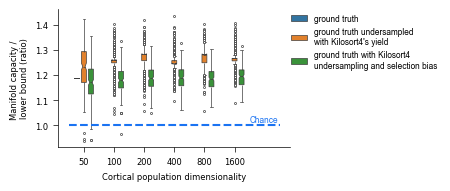

In [4]:
fig = plot_source_data(df)
plt.savefig(f"{OUT}/supp_fig8.svg", bbox_inches="tight", **savefig_cfg)

## Save source data

In [5]:
df.to_excel(f"{OUT}/supp_fig8.xlsx", sheet_name="capacity_bootstraps", index=False)

## Replot from the saved source data (the xlsx is sufficient to reproduce the figure)

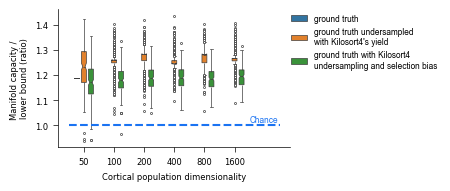

In [6]:
df = pd.read_excel(f"{OUT}/supp_fig8.xlsx")
fig = plot_source_data(df)